# GFC AI Chatbot — Task 1: Financial Data Extraction & Analysis
**BCG GenAI Consulting Team · Client: Global Finance Corp. (GFC)**
**Companies:** Microsoft, Tesla, Apple · **Period:** Fiscal years 2023–2025

## Objective
Extract key financial figures from the 10-K filings of Microsoft, Tesla and Apple, analyse year-over-year trends with pandas, and summarise each company's financial health. The cleaned dataset and the derived metrics will feed the AI-powered financial chatbot.

## Methodology
1. **Data extraction:** For each company, the FY2023, FY2024 and FY2025 10-K filings were located on SEC EDGAR. Five figures were taken from each: Total Revenue, Net Income, Total Assets, Total Liabilities and Cash Flow from Operating Activities. Values were cross-checked against the SEC's XBRL financial data for the same filings (accession numbers are in `financial_data.xlsx`).
2. **Organisation:** The data was compiled in `financial_data.xlsx` and exported to `financial_data.csv`.
3. **Analysis:** Data-quality checks, year-over-year (YoY) growth, financial ratios, 2-year CAGR and cross-company comparison.
4. **Summary:** Narrative findings and implications for the chatbot.

**Data notes**
- All figures are in **USD millions**, as reported in each fiscal year's own 10-K.
- Fiscal years differ: Microsoft ends 30 June, Apple ends late September, Tesla ends 31 December.
- Tesla's Net Income is net income attributable to common stockholders.

## 1. Setup and data loading

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:,.1f}'.format)
pd.set_option('display.width', 200)

df = pd.read_csv('financial_data.csv')
df

,Company,Year,Fiscal Year End,Total Revenue,Net Income,Total Assets,Total Liabilities,Cash Flow from Operating Activities
0,Microsoft,2023,2023-06-30,211915,72361,411976,205753,87582
1,Microsoft,2024,2024-06-30,245122,88136,512163,243686,118548
2,Microsoft,2025,2025-06-30,281724,101832,619003,275524,136162
3,Tesla,2023,2023-12-31,96773,14997,106618,43009,13256
4,Tesla,2024,2024-12-31,97690,7091,122070,48390,14923
5,Tesla,2025,2025-12-31,94827,3794,137806,54941,14747
6,Apple,2023,2023-09-30,383285,96995,352583,290437,110543
7,Apple,2024,2024-09-28,391035,93736,364980,308030,118254
8,Apple,2025,2025-09-27,416161,112010,359241,285508,111482


## 2. Data quality checks
Before analysis, I confirm the data types are correct, that nothing is missing or duplicated, and that each company has all three years.

In [2]:
df.info()
print('\nMissing values per column:\n', df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
print('\nYears per company:\n', df.groupby('Company')['Year'].count())

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 8 columns):
 #   Column                               Non-Null Count  Dtype
---  ------                               --------------  -----
 0   Company                              9 non-null      str  
 1   Year                                 9 non-null      int64
 2   Fiscal Year End                      9 non-null      str  
 3   Total Revenue                        9 non-null      int64
 4   Net Income                           9 non-null      int64
 5   Total Assets                         9 non-null      int64
 6   Total Liabilities                    9 non-null      int64
 7   Cash Flow from Operating Activities  9 non-null      int64
dtypes: int64(6), str(2)
memory usage: 708.0 bytes

Missing values per column:
 Company                                0
Year                                   0
Fiscal Year End                        0
Total Revenue                          0
Net Income                 

In [3]:
# Sanity check: liabilities should never exceed assets for these companies
assert (df['Total Liabilities'] < df['Total Assets']).all()
# Sort so that pct_change compares each year with the previous year of the same company
df = df.sort_values(['Company', 'Year']).reset_index(drop=True)
print('Data passed all checks.')

Data passed all checks.


## 3. Year-over-year growth
The percentage change from one year to the next for each metric, calculated within each company.

In [4]:
df['Revenue Growth (%)'] = df.groupby(['Company'])['Total Revenue'].pct_change() * 100
df['Net Income Growth (%)'] = df.groupby(['Company'])['Net Income'].pct_change() * 100
df['Assets Growth (%)'] = df.groupby(['Company'])['Total Assets'].pct_change() * 100
df['Liabilities Growth (%)'] = df.groupby(['Company'])['Total Liabilities'].pct_change() * 100
df['Operating Cash Flow Growth (%)'] = df.groupby(['Company'])['Cash Flow from Operating Activities'].pct_change() * 100

growth_cols = ['Revenue Growth (%)', 'Net Income Growth (%)', 'Assets Growth (%)',
               'Liabilities Growth (%)', 'Operating Cash Flow Growth (%)']
df[['Company', 'Year'] + growth_cols]

,Company,Year,Revenue Growth (%),Net Income Growth (%),Assets Growth (%),Liabilities Growth (%),Operating Cash Flow Growth (%)
0,Apple,2023,NaN,NaN,NaN,NaN,NaN
1,Apple,2024,2.0,-3.4,3.5,6.1,7.0
2,Apple,2025,6.4,19.5,-1.6,-7.3,-5.7
3,Microsoft,2023,NaN,NaN,NaN,NaN,NaN
4,Microsoft,2024,15.7,21.8,24.3,18.4,35.4
5,Microsoft,2025,14.9,15.5,20.9,13.1,14.9
6,Tesla,2023,NaN,NaN,NaN,NaN,NaN
7,Tesla,2024,0.9,-52.7,14.5,12.5,12.6
8,Tesla,2025,-2.9,-46.5,12.9,13.5,-1.2


*FY2023 shows `NaN` because there is no FY2022 value in the dataset to compare against.*

## 4. Feature engineering: financial ratios
Raw figures are hard to compare across companies of different sizes, so I derive ratios:

| Ratio | Formula | What it tells us |
|---|---|---|
| Net Profit Margin (%) | Net Income ÷ Revenue | Profitability: how much of each dollar of sales is kept as profit |
| Liabilities-to-Assets (%) | Total Liabilities ÷ Total Assets | Leverage: how much of the asset base is financed by obligations |
| Implied Equity | Total Assets − Total Liabilities | The book value left for shareholders |
| Debt-to-Equity (x) | Total Liabilities ÷ Implied Equity | Leverage relative to shareholders' capital |
| Operating Cash Flow Margin (%) | Operating Cash Flow ÷ Revenue | How efficiently sales turn into cash |
| Cash Conversion (x) | Operating Cash Flow ÷ Net Income | Earnings quality: values ≥ 1 mean profits are backed by cash |

In [5]:
df['Net Profit Margin (%)'] = df['Net Income'] / df['Total Revenue'] * 100
df['Liabilities-to-Assets (%)'] = df['Total Liabilities'] / df['Total Assets'] * 100
df['Implied Equity'] = df['Total Assets'] - df['Total Liabilities']
df['Debt-to-Equity (x)'] = df['Total Liabilities'] / df['Implied Equity']
df['OCF Margin (%)'] = df['Cash Flow from Operating Activities'] / df['Total Revenue'] * 100
df['Cash Conversion (x)'] = df['Cash Flow from Operating Activities'] / df['Net Income']

ratio_cols = ['Net Profit Margin (%)', 'Liabilities-to-Assets (%)', 'Implied Equity',
              'Debt-to-Equity (x)', 'OCF Margin (%)', 'Cash Conversion (x)']
df[['Company', 'Year'] + ratio_cols]

,Company,Year,Net Profit Margin (%),Liabilities-to-Assets (%),Implied Equity,Debt-to-Equity (x),OCF Margin (%),Cash Conversion (x)
0,Apple,2023,25.3,82.4,62146,4.7,28.8,1.1
1,Apple,2024,24.0,84.4,56950,5.4,30.2,1.3
2,Apple,2025,26.9,79.5,73733,3.9,26.8,1.0
3,Microsoft,2023,34.1,49.9,206223,1.0,41.3,1.2
4,Microsoft,2024,36.0,47.6,268477,0.9,48.4,1.3
5,Microsoft,2025,36.1,44.5,343479,0.8,48.3,1.3
6,Tesla,2023,15.5,40.3,63609,0.7,13.7,0.9
7,Tesla,2024,7.3,39.6,73680,0.7,15.3,2.1
8,Tesla,2025,4.0,39.9,82865,0.7,15.6,3.9


## 5. Aggregations across companies and years

### 5.1 Average YoY growth by company (FY2024–FY2025)

In [6]:
df.groupby('Company')[growth_cols].mean().round(1)

,Revenue Growth (%),Net Income Growth (%),Assets Growth (%),Liabilities Growth (%),Operating Cash Flow Growth (%)
Company,,,,,
Apple,4.2,8.1,1.0,-0.6,0.6
Microsoft,15.3,18.7,22.6,15.8,25.1
Tesla,-1.0,-49.6,13.7,13.0,5.7


### 5.2 Two-year compound annual growth rate (FY2023 → FY2025)

In [7]:
metrics = ['Total Revenue', 'Net Income', 'Total Assets', 'Total Liabilities',
           'Cash Flow from Operating Activities']
first = df[df['Year'] == 2023].set_index('Company')[metrics]
last = df[df['Year'] == 2025].set_index('Company')[metrics]
cagr = ((last / first) ** (1 / 2) - 1) * 100
cagr.round(1).add_suffix(' CAGR (%)')

,Total Revenue CAGR (%),Net Income CAGR (%),Total Assets CAGR (%),Total Liabilities CAGR (%),Cash Flow from Operating Activities CAGR (%)
Company,,,,,
Apple,4.2,7.5,0.9,-0.9,0.4
Microsoft,15.3,18.6,22.6,15.7,24.7
Tesla,-1.0,-49.7,13.7,13.0,5.5


### 5.3 Average ratios by company (FY2023–FY2025)

In [8]:
df.groupby('Company')[ratio_cols].mean().round(2)

,Net Profit Margin (%),Liabilities-to-Assets (%),Implied Equity,Debt-to-Equity (x),OCF Margin (%),Cash Conversion (x)
Company,,,,,,
Apple,25.4,82.1,"64,276.3",4.7,28.6,1.1
Microsoft,35.4,47.3,"272,726.3",0.9,46.0,1.3
Tesla,8.9,40.0,"73,384.7",0.7,14.8,2.3


### 5.4 Latest year (FY2025) side-by-side comparison

In [9]:
latest = df[df['Year'] == 2025].set_index('Company')
latest[metrics + ['Net Profit Margin (%)', 'Liabilities-to-Assets (%)', 'Cash Conversion (x)']].T

Company,Apple,Microsoft,Tesla
Total Revenue,"416,161.0","281,724.0","94,827.0"
Net Income,"112,010.0","101,832.0","3,794.0"
Total Assets,"359,241.0","619,003.0","137,806.0"
Total Liabilities,"285,508.0","275,524.0","54,941.0"
Cash Flow from Operating Activities,"111,482.0","136,162.0","14,747.0"
Net Profit Margin (%),26.9,36.1,4.0
Liabilities-to-Assets (%),79.5,44.5,39.9
Cash Conversion (x),1.0,1.3,3.9


### 5.5 Pivot view: revenue and net income by year

In [10]:
df.pivot_table(index='Year', columns='Company', values=['Total Revenue', 'Net Income'])

Net Income                    Total Revenue                   
Company      Apple Microsoft    Tesla         Apple Microsoft    Tesla
Year                                                                  
2023      96,995.0  72,361.0 14,997.0     383,285.0 211,915.0 96,773.0
2024      93,736.0  88,136.0  7,091.0     391,035.0 245,122.0 97,690.0
2025     112,010.0 101,832.0  3,794.0     416,161.0 281,724.0 94,827.0

## 6. Visualising the trends

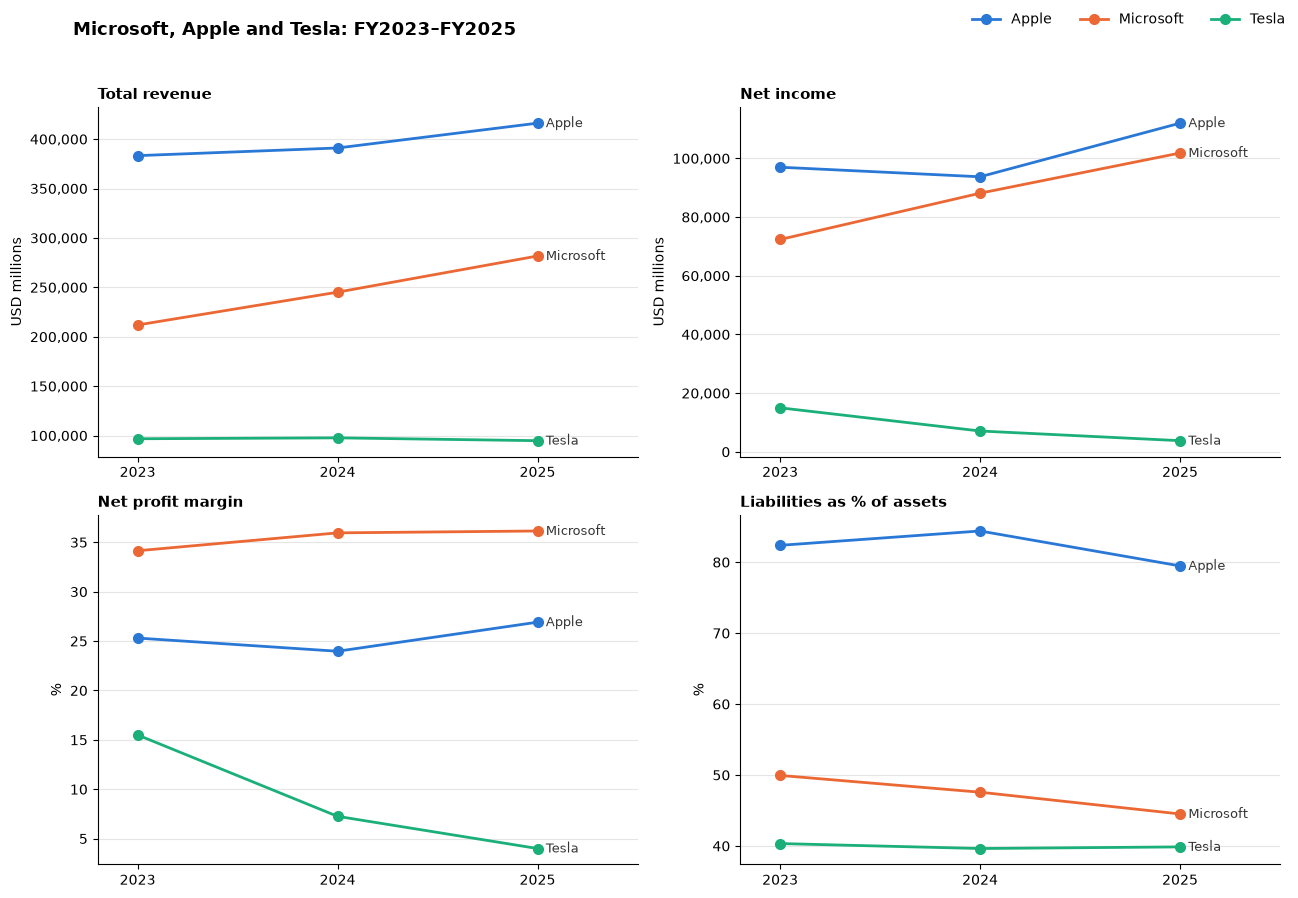

In [11]:
colors = {'Apple': '#2a78d6', 'Microsoft': '#eb6834', 'Tesla': '#1baf7a'}  # fixed colour per company
years = sorted(df['Year'].unique())

def line_chart(ax, col, title, ylabel):
    for co, g in df.groupby('Company'):
        ax.plot(g['Year'], g[col], marker='o', linewidth=2, markersize=7, color=colors[co], label=co)
        ax.annotate(co, (g['Year'].iloc[-1], g[col].iloc[-1]), xytext=(6, 0),
                    textcoords='offset points', va='center', fontsize=9, color='#333333')
    ax.set_title(title, loc='left', fontsize=11, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.set_xticks(years)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax.set_xlim(years[0] - 0.2, years[-1] + 0.5)
    ax.grid(axis='y', color='#e5e5e5'); ax.set_axisbelow(True)
    for s in ['top', 'right']: ax.spines[s].set_visible(False)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
line_chart(axes[0, 0], 'Total Revenue', 'Total revenue', 'USD millions')
line_chart(axes[0, 1], 'Net Income', 'Net income', 'USD millions')
line_chart(axes[1, 0], 'Net Profit Margin (%)', 'Net profit margin', '%')
line_chart(axes[1, 1], 'Liabilities-to-Assets (%)', 'Liabilities as % of assets', '%')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', ncol=3, frameon=False)
fig.suptitle('Microsoft, Apple and Tesla: FY2023–FY2025', x=0.06, ha='left', fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 7. Findings

### Microsoft: strongest growth and financial health
- **Revenue** grew from \$211.9B (FY2023) to \$281.7B (FY2025): +15.7% then +14.9%, a **~15.3% two-year CAGR**, the fastest of the three.
- **Net income** rose from \$72.4B to \$101.8B (+21.8%, then +15.5%), with profit growing faster than revenue.
- **Net margin is the highest of the group and rising** (34.1% → 36.1%).
- **Total assets grew ~50%** (\$412.0B → \$619.0B), reflecting heavy investment (for example, cloud and AI infrastructure), while **liabilities as a share of assets fell** from 49.9% to 44.5%. Growth is mainly financed by equity and earnings, not debt.
- **Operating cash flow** jumped from \$87.6B to \$136.2B. Cash conversion of about 1.3x means profits are strongly backed by cash.

### Apple: largest and very profitable, but slower growth and higher leverage
- **Revenue is the largest** of the three: \$383.3B → \$416.2B, but growth is modest (+2.0%, then +6.4%; ~4.2% CAGR).
- **Net income** dipped 3.4% in FY2024 (\$93.7B), then rebounded 19.5% to a record **\$112.0B** in FY2025.
- **Net margin is stable and high** at about 24–27%.
- **Liabilities are about 80% of assets** (debt-to-equity of about 3.9–5.4x), the highest leverage of the three. This reflects Apple's long-running share buybacks shrinking book equity rather than financial distress, since operating cash flow (\$110–118B a year) easily covers its obligations. Leverage improved in FY2025 (84.4% → 79.5%).
- **Cash conversion of about 1.0–1.3x** shows high-quality earnings.

### Tesla: growing its asset base, but profitability under pressure
- **Revenue is flat to declining**: \$96.8B → \$97.7B → \$94.8B (+0.9%, then −2.9%).
- **Net income fell sharply**: \$15.0B → \$7.1B (−52.7%) → \$3.8B (−46.5%). FY2023's profit was boosted by a large one-time, non-cash tax benefit disclosed in that year's 10-K, which exaggerates the FY2024 decline. Even so, the downward trend continued into FY2025.
- **Net margin compressed** from 15.5% to 4.0%, consistent with price cuts and competitive pressure in EVs.
- **The balance sheet stays conservative**: liabilities are about 40% of assets, the lowest of the three, and total assets grew about 29% (\$106.6B → \$137.8B).
- **Operating cash flow is resilient** at about \$13–15B a year despite the falling profits. Cash conversion of 2.1x and 3.9x shows cash generation is much stronger than reported net income.

### Cross-company comparison
| | Growth | Profitability | Leverage | Cash generation |
|---|---|---|---|---|
| **Microsoft** | High (~15% revenue CAGR) | Highest (~36% margin) | Low and falling | Strong and rising |
| **Apple** | Low to moderate (~4%) | High (~25%) | High (buyback-driven) | Strong and stable |
| **Tesla** | Flat or negative | Low and falling (4%) | Lowest | Stable |

## 8. Summary: financial health
- **Microsoft** is in the strongest overall position: fast, profitable growth funded by cash rather than debt.
- **Apple** is a highly profitable, cash-rich business. Its high liabilities ratio is a deliberate capital-return strategy, not a sign of distress, and growth re-accelerated in FY2025.
- **Tesla** has a solid, low-leverage balance sheet and steady operating cash flow, but falling revenue and sharply lower margins are the key risk to watch.

## 9. Implications for the AI chatbot
- **Data structure:** A tidy table (one row per company and year) with raw figures plus derived growth and ratio columns lets the chatbot answer both lookup questions ("What was Apple's FY2025 revenue?") and analytical ones ("Whose margin is falling?").
- **Context matters:** The chatbot must state the fiscal-year end dates and flag one-time items (such as Tesla's FY2023 tax benefit) so users don't misread trends.
- **Scalability:** Pulling the data from SEC XBRL (structured 10-K data) instead of reading PDFs would let the pipeline scale to many companies and quarters (10-Qs) automatically.
- **Next step:** Use this cleaned dataset as the knowledge base for the chatbot prototype in Task 2.

## Appendix: final enriched dataset

In [12]:
df.to_csv('financial_data_enriched.csv', index=False)
df

,Company,Year,Fiscal Year End,Total Revenue,Net Income,Total Assets,Total Liabilities,Cash Flow from Operating Activities,Revenue Growth (%),Net Income Growth (%),Assets Growth (%),Liabilities Growth (%),Operating Cash Flow Growth (%),Net Profit Margin (%),Liabilities-to-Assets (%),Implied Equity,Debt-to-Equity (x),OCF Margin (%),Cash Conversion (x)
0,Apple,2023,2023-09-30,383285,96995,352583,290437,110543,NaN,NaN,NaN,NaN,NaN,25.3,82.4,62146,4.7,28.8,1.1
1,Apple,2024,2024-09-28,391035,93736,364980,308030,118254,2.0,-3.4,3.5,6.1,7.0,24.0,84.4,56950,5.4,30.2,1.3
2,Apple,2025,2025-09-27,416161,112010,359241,285508,111482,6.4,19.5,-1.6,-7.3,-5.7,26.9,79.5,73733,3.9,26.8,1.0
3,Microsoft,2023,2023-06-30,211915,72361,411976,205753,87582,NaN,NaN,NaN,NaN,NaN,34.1,49.9,206223,1.0,41.3,1.2
4,Microsoft,2024,2024-06-30,245122,88136,512163,243686,118548,15.7,21.8,24.3,18.4,35.4,36.0,47.6,268477,0.9,48.4,1.3
5,Microsoft,2025,2025-06-30,281724,101832,619003,275524,136162,14.9,15.5,20.9,13.1,14.9,36.1,44.5,343479,0.8,48.3,1.3
6,Tesla,2023,2023-12-31,96773,14997,106618,43009,13256,NaN,NaN,NaN,NaN,NaN,15.5,40.3,63609,0.7,13.7,0.9
7,Tesla,2024,2024-12-31,97690,7091,122070,48390,14923,0.9,-52.7,14.5,12.5,12.6,7.3,39.6,73680,0.7,15.3,2.1
8,Tesla,2025,2025-12-31,94827,3794,137806,54941,14747,-2.9,-46.5,12.9,13.5,-1.2,4.0,39.9,82865,0.7,15.6,3.9
